<a href="https://colab.research.google.com/github/uf16/sp-500-analysis/blob/main/Estacionalidad_Sectores_SP500_2021_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [120]:
import yfinance as yf
precios = yf.download(tickers = ['XLK', 'XLF', 'XLV', 'XLE', 'XLY', 'XLP', 'XLI', 'XLB', 'XLU', 'XLRE', 'XLC'], start = '2021-01-01', end='2026-01-01', interval='1mo')['Close']

/tmp/ipykernel_572/3870367136.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  precios = yf.download(tickers = ['XLK', 'XLF', 'XLV', 'XLE', 'XLY', 'XLP', 'XLI', 'XLB', 'XLU', 'XLRE', 'XLC'], start = '2021-01-01', end='2026-01-01', interval='1mo')['Close']
[*********************100%***********************]  11 of 11 completed


### Paso 2: Cálculo de Retornos y Transformación de Datos (Melt)
En esta celda calcularemos los retornos mensuales, extraeremos el mes de cada fecha y transformaremos el DataFrame de formato ancho a largo para su posterior almacenamiento.

In [121]:
retornos = precios.pct_change().dropna() * 100

In [122]:
retornos['Mes'] = retornos.index.month
retornos = retornos.reset_index()
df_final = retornos.melt(id_vars = ['Date', 'Mes'], var_name= 'Ticker', value_name = 'Retorno_Pct')

In [123]:
import sqlite3
import pandas as pd
conexion = sqlite3.connect('sectores.db')
df_final.to_sql('Retornos', con=conexion, if_exists='replace', index=False)


649

In [124]:
mapeo_sectores = {
    'XLB': 'Materials',
    'XLC': 'Communication Services',
    'XLE': 'Energy',
    'XLF': 'Financials',
    'XLI': 'Industrials',
    'XLK': 'Technology',
    'XLP': 'Consumer Staples',
    'XLRE': 'Real Estate',
    'XLU': 'Utilities',
    'XLV': 'Health Care',
    'XLY': 'Consumer Discretionary'
}

df_mapeo_sectores = pd.DataFrame(list(mapeo_sectores.items()), columns=['Ticker', 'Sector'])
df_mapeo_sectores.to_sql('Sectores', con=conexion, if_exists='replace', index=False)

11

In [125]:
consulta_sql = "SELECT * FROM Retornos LIMIT 5"
df_resultado = pd.read_sql_query(consulta_sql, conexion)
df_resultado

,Date,Mes,Ticker,Retorno_Pct
0,2021-02-01 00:00:00,2,XLB,4.119476
1,2021-03-01 00:00:00,3,XLB,7.590461
2,2021-04-01 00:00:00,4,XLB,5.380703
3,2021-05-01 00:00:00,5,XLB,5.081883
4,2021-06-01 00:00:00,6,XLB,-5.263179


In [126]:
def sql(query):
    return pd.read_sql_query(query, conexion)

conexion.execute('DROP VIEW IF EXISTS vista_retornos_sectores')
conexion.commit()

conexion.execute('create view vista_retornos_sectores as select Date, Retornos.Ticker, Retorno_Pct, Sector, Mes from Retornos Join Sectores on Retornos.Ticker = Sectores.Ticker')
conexion.commit()

In [127]:
sql('select avg(Retorno_Pct), Sector from vista_retornos_sectores group by Sector order by avg(Retorno_Pct) desc')

,avg(Retorno_Pct),Sector
0,2.004633,Energy
1,1.615307,Technology
2,1.372884,Financials
3,1.289407,Industrials
4,1.189905,Communication Services
5,0.927443,Consumer Discretionary
6,0.916635,Utilities
7,0.748234,Materials
8,0.726293,Health Care
9,0.615444,Consumer Staples


In [128]:
conexion.execute('DROP VIEW IF EXISTS final_table')
conexion.commit()
conexion.execute('CREATE VIEW final_table as select Ticker, avg(Retorno_Pct), Sector, Mes, COUNT(*) AS Total_Years, COUNT(CASE WHEN Retorno_Pct < 0 THEN 1 END) AS Meses_Negativos, COUNT(CASE WHEN Retorno_Pct < 0 THEN 1 END) * 100 / COUNT(*)  As Negative_Percentage, MIN(Retorno_Pct) AS Peor_Pct, MAX(Retorno_Pct) AS Mejor_Pct, MAX(Retorno_Pct) - MIN(Retorno_Pct) AS Amplitud_Pct from vista_retornos_sectores group by Mes, Ticker order by avg(Retorno_Pct)')
conexion.commit()

In [129]:
sql('select * from final_table')

,Ticker,avg(Retorno_Pct),Sector,Mes,Total_Years,Meses_Negativos,Negative_Percentage,Peor_Pct,Mejor_Pct,Amplitud_Pct
0,XLRE,-4.606596,Real Estate,9,5,3,60,-13.171301,3.290731,16.462032
1,XLB,-4.201712,Materials,9,5,4,80,-9.302930,2.683683,11.986613
2,XLP,-3.649834,Consumer Staples,9,5,4,80,-8.132867,1.128424,9.261291
3,XLI,-3.443323,Industrials,9,5,3,60,-10.430947,3.362054,13.793000
4,XLK,-2.820634,Technology,9,5,3,60,-11.967110,7.533680,19.500790
...,...,...,...,...,...,...,...,...,...,...
127,XLY,5.296684,Consumer Discretionary,7,5,0,0,1.052921,18.439079,17.386157
128,XLE,5.817235,Energy,10,5,2,40,-5.752821,24.965300,30.718121
129,XLE,5.846436,Energy,1,4,1,25,-0.512895,18.774793,19.287688
130,XLE,5.938816,Energy,2,5,1,20,-6.938721,22.456759,29.395481


In [130]:
sql('select * from final_table order by Negative_Percentage desc')

,Ticker,avg(Retorno_Pct),Sector,Mes,Total_Years,Meses_Negativos,Negative_Percentage,Peor_Pct,Mejor_Pct,Amplitud_Pct
0,XLB,-4.201712,Materials,9,5,4,80,-9.302930,2.683683,11.986613
1,XLP,-3.649834,Consumer Staples,9,5,4,80,-8.132867,1.128424,9.261291
2,XLF,-2.607876,Financials,9,5,4,80,-7.655952,0.106180,7.762132
3,XLY,-2.244619,Consumer Discretionary,4,5,4,80,-11.956769,6.455647,18.412416
4,XLV,-2.188902,Health Care,9,5,4,80,-5.518413,1.729220,7.247633
...,...,...,...,...,...,...,...,...,...,...
127,XLI,4.257567,Industrials,7,5,0,0,0.937473,9.503082,8.565609
128,XLU,4.801201,Utilities,7,5,0,0,2.490814,6.824181,4.333367
129,XLE,5.258905,Energy,3,5,0,0,0.005331,10.486384,10.481054
130,XLY,5.296684,Consumer Discretionary,7,5,0,0,1.052921,18.439079,17.386157


In [131]:
sql('select * from final_table order by "avg(Retorno_Pct)" asc')

,Ticker,avg(Retorno_Pct),Sector,Mes,Total_Years,Meses_Negativos,Negative_Percentage,Peor_Pct,Mejor_Pct,Amplitud_Pct
0,XLRE,-4.606596,Real Estate,9,5,3,60,-13.171301,3.290731,16.462032
1,XLB,-4.201712,Materials,9,5,4,80,-9.302930,2.683683,11.986613
2,XLP,-3.649834,Consumer Staples,9,5,4,80,-8.132867,1.128424,9.261291
3,XLI,-3.443323,Industrials,9,5,3,60,-10.430947,3.362054,13.793000
4,XLK,-2.820634,Technology,9,5,3,60,-11.967110,7.533680,19.500790
...,...,...,...,...,...,...,...,...,...,...
127,XLY,5.296684,Consumer Discretionary,7,5,0,0,1.052921,18.439079,17.386157
128,XLE,5.817235,Energy,10,5,2,40,-5.752821,24.965300,30.718121
129,XLE,5.846436,Energy,1,4,1,25,-0.512895,18.774793,19.287688
130,XLE,5.938816,Energy,2,5,1,20,-6.938721,22.456759,29.395481


In [132]:
from operator import index
final_sql = sql('select Sector, Mes, "avg(Retorno_Pct)" from final_table')
matriz_retornos = final_sql.pivot(index='Sector', columns='Mes', values='avg(Retorno_Pct)')

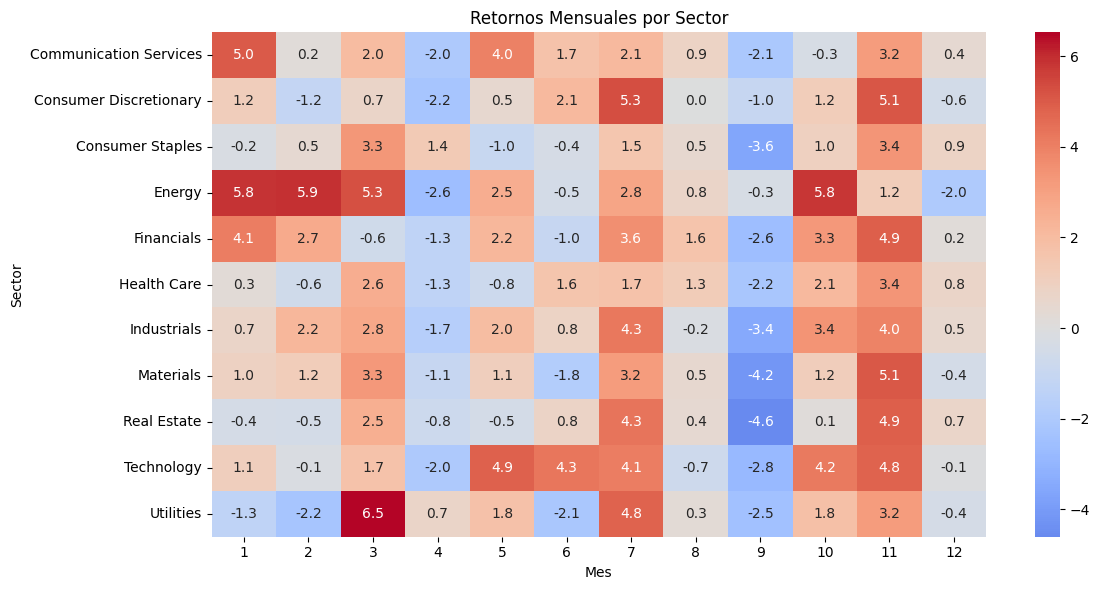

In [133]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
sns.heatmap(matriz_retornos, cmap='coolwarm', center = 0, annot = True, fmt=".1f")
plt.title('Retornos Mensuales por Sector')
plt.tight_layout()
plt.show()
